In [4]:
import sys 

print(sys.executable)
print(sys.version)

c:\Users\HP\OneDrive\Desktop\Documents\ML_Projects\banking_intent_classifier\.venv\Scripts\python.exe
3.13.2 (tags/v3.13.2:4f8bb39, Feb  4 2025, 15:23:48) [MSC v.1942 64 bit (AMD64)]


In [5]:
import numpy as np 
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [6]:
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("Scikit_learn:", __import__("sklearn").__version__)

Pandas: 3.0.6
Numpy: 2.5.3
Scikit_learn: 1.9.1


In [7]:
DATA_DIR = Path("../data")

train_path = DATA_DIR / "train.csv"
test_path = DATA_DIR / "test.csv"

In [8]:
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

In [9]:
print("Training shape: ", train_df.shape)
print("Test shape: ", test_df.shape)

Training shape:  (10003, 2)
Test shape:  (3080, 2)


In [10]:
train_df.head()

,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [11]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      10003 non-null  str  
 1   category  10003 non-null  str  
dtypes: str(2)
memory usage: 156.4 KB


In [12]:
train_df.isnull().sum()

text        0
category    0
dtype: int64

In [13]:
train_df.duplicated().sum()

np.int64(0)

In [14]:
train_df["category"].value_counts()

category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
                                                   ... 
lost_or_stolen_card                                  82
card_swallowed                                       61
card_acceptance                                      59
virtual_card_not_working                             41
contactless_not_working                              35
Name: count, Length: 77, dtype: int64

In [15]:
train_df["category"].nunique()

77

In [16]:
category_counts = train_df["category"].value_counts()

category_counts.head()

category
card_payment_fee_charged                            187
direct_debit_payment_not_recognised                 182
balance_not_updated_after_cheque_or_cash_deposit    181
wrong_amount_of_cash_received                       180
cash_withdrawal_charge                              177
Name: count, dtype: int64

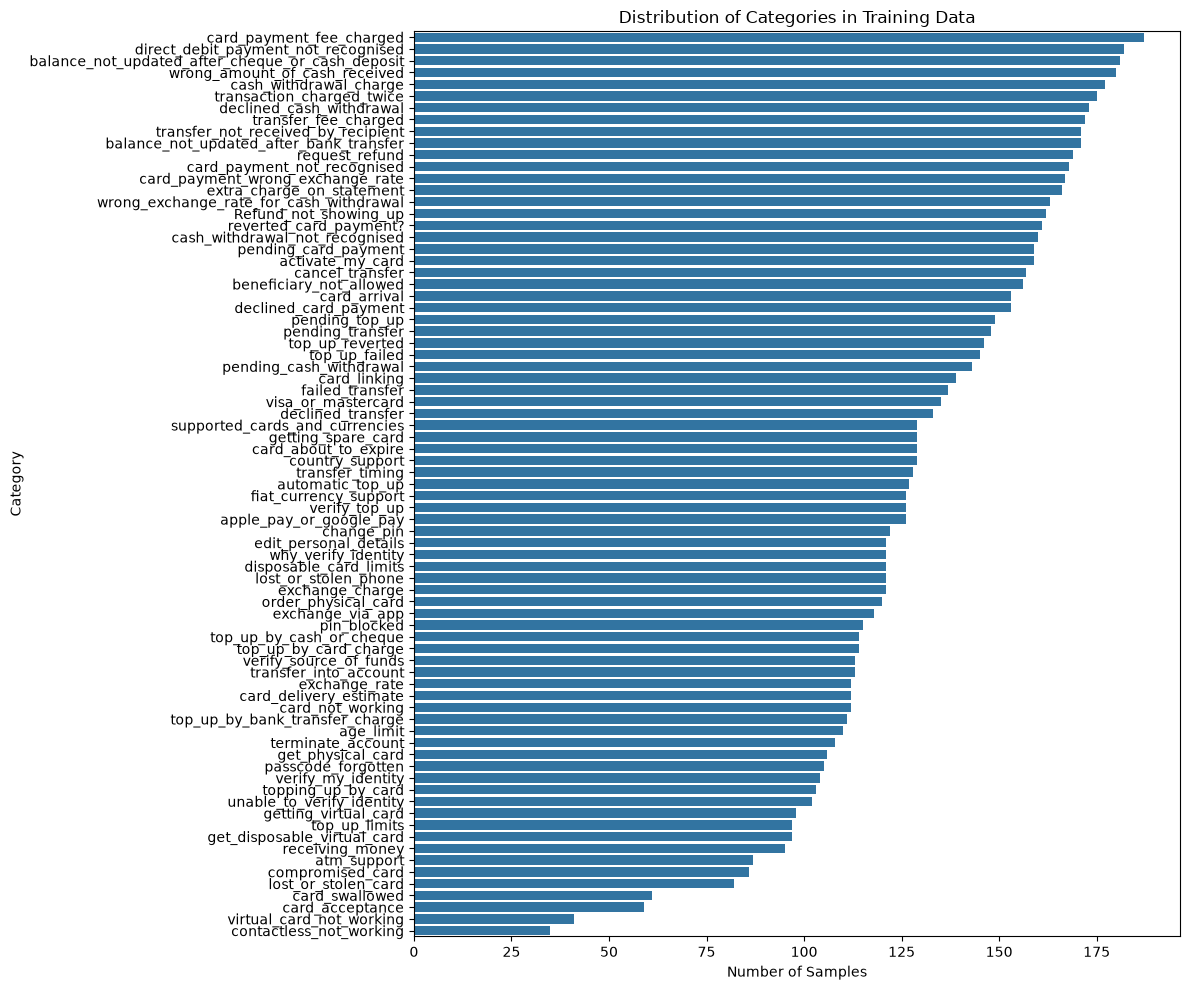

In [17]:
plt.figure(figsize=(12,10))

sns.barplot(
    x = category_counts.values,
    y = category_counts.index
)

plt.title("Distribution of Categories in Training Data")
plt.xlabel("Number of Samples")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [18]:
train_df["word_count"] = train_df["text"].str.split().apply(len)

In [19]:
train_df["word_count"].describe()

count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: word_count, dtype: float64

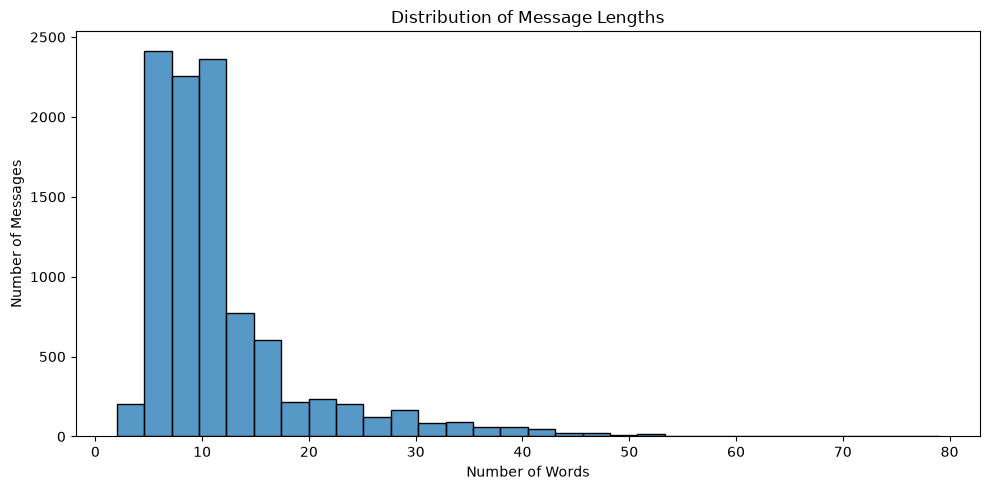

In [20]:
plt.figure(figsize=(10, 5))

sns.histplot(train_df["word_count"], bins=30)

plt.title("Distribution of Message Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

In [21]:
train_df["text"].duplicated().sum()

np.int64(0)

In [22]:

train_df.groupby("text")["category"].nunique().gt(1).sum()

np.int64(0)

In [23]:
train_df[["text", "category"]].sample(10, random_state=42)

,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer
5573,Why am I getting declines when trying to make ...,declined_transfer
576,What is the $1 transaction on my account?,extra_charge_on_statement
6832,It looks like my card payment was sent back.,reverted_card_payment?
7111,Why am I unable to transfer money when I was a...,beneficiary_not_allowed
439,What if there is an error on the exchange rate?,card_payment_wrong_exchange_rate


In [24]:
examples = (
    train_df
    .groupby("category", group_keys=False)
    .sample(n=1, random_state=42)
)

examples[["category", "text"]]

,category,text
5832,Refund_not_showing_up,I made a big purchase that I regretted and can...
9193,activate_my_card,i cant seem to activate card
1648,age_limit,My daughter needs to open account.
9699,apple_pay_or_google_pay,Are top-ups allowed using Apple Pay?
4623,atm_support,I need to know where I can withdraw money.
...,...,...
8183,virtual_card_not_working,I can't use my virtual disposable card
4115,visa_or_mastercard,"Can you send me a Mastercard, instead of a Visa?"
3861,why_verify_identity,Why is verifaction required for my Identity?
2379,wrong_amount_of_cash_received,What do I need to do to get cash back? The ATM...


In [25]:
for category in sorted(train_df["category"].unique()):
    print(category)

Refund_not_showing_up
activate_my_card
age_limit
apple_pay_or_google_pay
atm_support
automatic_top_up
balance_not_updated_after_bank_transfer
balance_not_updated_after_cheque_or_cash_deposit
beneficiary_not_allowed
cancel_transfer
card_about_to_expire
card_acceptance
card_arrival
card_delivery_estimate
card_linking
card_not_working
card_payment_fee_charged
card_payment_not_recognised
card_payment_wrong_exchange_rate
card_swallowed
cash_withdrawal_charge
cash_withdrawal_not_recognised
change_pin
compromised_card
contactless_not_working
country_support
declined_card_payment
declined_cash_withdrawal
declined_transfer
direct_debit_payment_not_recognised
disposable_card_limits
edit_personal_details
exchange_charge
exchange_rate
exchange_via_app
extra_charge_on_statement
failed_transfer
fiat_currency_support
get_disposable_virtual_card
get_physical_card
getting_spare_card
getting_virtual_card
lost_or_stolen_card
lost_or_stolen_phone
order_physical_card
passcode_forgotten
pending_card_payment

In [26]:
card_intents = [
    category 
    for category in train_df["category"].unique()
    if "card" in category.lower()
]

card_intents

['card_arrival',
 'card_linking',
 'card_payment_wrong_exchange_rate',
 'card_delivery_estimate',
 'card_not_working',
 'lost_or_stolen_card',
 'card_payment_fee_charged',
 'supported_cards_and_currencies',
 'getting_virtual_card',
 'card_acceptance',
 'card_payment_not_recognised',
 'get_physical_card',
 'visa_or_mastercard',
 'topping_up_by_card',
 'disposable_card_limits',
 'compromised_card',
 'pending_card_payment',
 'declined_card_payment',
 'card_swallowed',
 'reverted_card_payment?',
 'getting_spare_card',
 'order_physical_card',
 'virtual_card_not_working',
 'get_disposable_virtual_card',
 'top_up_by_card_charge',
 'activate_my_card',
 'card_about_to_expire']

In [27]:
X = train_df["text"]
y = train_df["category"]

In [28]:
train_df = train_df.drop(columns= ["word_count"])

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X,y, test_size = 0.10, random_state=42 , stratify = y)

In [30]:
print("Training samples: ", len(X_train))
print("Validation samples: ", len(X_val))
print("test samples: ", len(test_df))

Training samples:  9002
Validation samples:  1001
test samples:  3080


In [31]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [32]:
tfidf = TfidfVectorizer(
    ngram_range = (1,2),
    min_df = 2,
    sublinear_tf = True

)

In [33]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [34]:
X_val_tfidf = tfidf.transform(X_val)

In [35]:
print("training TF-IDF shape: ",X_train_tfidf.shape)
print("validation TF-IDF shape: ",X_val_tfidf.shape)

training TF-IDF shape:  (9002, 9640)
validation TF-IDF shape:  (1001, 9640)


In [36]:
print(X_train_tfidf.shape)
print(X_val_tfidf.shape)

(9002, 9640)
(1001, 9640)


In [37]:
from sklearn.linear_model import LogisticRegression
import time

logreg = LogisticRegression(max_iter = 1000)

start = time.time()
logreg.fit(X_train_tfidf, y_train)
training_time = time.time() - start

In [38]:
from sklearn.metrics import accuracy_score, f1_score

start = time.time()

y_val_pred = logreg.predict(X_val_tfidf)

prediction_time = time.time() - start

In [39]:
logreg_accuracy = accuracy_score(y_val, y_val_pred)
logreg_macro_f1 = f1_score(y_val, y_val_pred, average="macro")
logreg_weighted_f1 = f1_score(y_val, y_val_pred, average="weighted")

print("Accuracy:", logreg_accuracy)
print("Macro F1:", logreg_macro_f1)
print("Weighted F1:", logreg_weighted_f1)
print("Training time:", training_time)
print("Prediction time:", prediction_time)


Accuracy: 0.8591408591408591
Macro F1: 0.8563396156872632
Weighted F1: 0.8580046169343807
Training time: 62.31489539146423
Prediction time: 0.013668537139892578


In [40]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC()

start = time.time()

svm_model.fit(X_train_tfidf, y_train)

svm_training_time = time.time() - start

In [41]:
start = time.time()

y_val_pred_svm = svm_model.predict(X_val_tfidf)

svm_prediction_time = time.time() - start

In [42]:
svm_accuracy = accuracy_score(y_val, y_val_pred_svm)
svm_macro_f1 = f1_score(y_val, y_val_pred_svm, average="macro")
svm_weighted_f1 = f1_score(y_val, y_val_pred_svm, average="weighted")

print("Accuracy:", svm_accuracy)
print("Macro F1:", svm_macro_f1)
print("Weighted F1:", svm_weighted_f1)
print("Training time:", svm_training_time)
print("Prediction time:", svm_prediction_time)

Accuracy: 0.8901098901098901
Macro F1: 0.8911770406239142
Weighted F1: 0.8896307549011453
Training time: 6.351726055145264
Prediction time: 0.012121915817260742


In [43]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

start = time.time()

nb_model.fit(X_train_tfidf, y_train)

nb_training_time = time.time() - start

In [44]:
start = time.time()

y_val_pred_nb = nb_model.predict(X_val_tfidf)

nb_prediction_time = time.time() - start




In [45]:
nb_accuracy = accuracy_score(y_val, y_val_pred_nb)
nb_macro_f1 = f1_score(y_val, y_val_pred_nb, average="macro")
nb_weighted_f1 = f1_score(y_val, y_val_pred_nb, average="weighted")

print("Accuracy:", nb_accuracy)
print("Macro F1:", nb_macro_f1)
print("Weighted F1:", nb_weighted_f1)
print("Training time:", nb_training_time)
print("Prediction time:", nb_prediction_time)

Accuracy: 0.8251748251748252
Macro F1: 0.7970404409601239
Weighted F1: 0.8194712828662507
Training time: 0.8464086055755615
Prediction time: 0.024279117584228516


In [46]:
from sklearn.naive_bayes import ComplementNB

cnb_model = ComplementNB()

start = time.time()

cnb_model.fit(X_train_tfidf, y_train)

cnb_training_time = time.time() - start

In [47]:
start = time.time()

y_val_pred_cnb = cnb_model.predict(X_val_tfidf)

cnb_prediction_time = time.time() - start

In [48]:
cnb_accuracy = accuracy_score(y_val, y_val_pred_cnb)
cnb_macro_f1 = f1_score(y_val, y_val_pred_cnb, average="macro")
cnb_weighted_f1 = f1_score(y_val, y_val_pred_cnb, average="weighted")

print("Accuracy:", cnb_accuracy)
print("Macro F1:", cnb_macro_f1)
print("Weighted F1:", cnb_weighted_f1)
print("Training time:", cnb_training_time)
print("Prediction time:", cnb_prediction_time)

Accuracy: 0.8041958041958042
Macro F1: 0.7964833011058652
Weighted F1: 0.7995544384853
Training time: 0.670297384262085
Prediction time: 0.019102811813354492


In [49]:
from sklearn.linear_model import SGDClassifier

sgd_model = SGDClassifier(
    loss="hinge",
    random_state=42
)

start = time.time()

sgd_model.fit(X_train_tfidf, y_train)

sgd_training_time = time.time() - start

In [50]:
start = time.time()

y_val_pred_sgd = sgd_model.predict(X_val_tfidf)

sgd_prediction_time = time.time() - start

In [51]:
sgd_accuracy = accuracy_score(y_val, y_val_pred_sgd)
sgd_macro_f1 = f1_score(y_val, y_val_pred_sgd, average="macro")
sgd_weighted_f1 = f1_score(y_val, y_val_pred_sgd, average="weighted")

print("Accuracy:", sgd_accuracy)
print("Macro F1:", sgd_macro_f1)
print("Weighted F1:", sgd_weighted_f1)
print("Training time:", sgd_training_time)
print("Prediction time:", sgd_prediction_time)

Accuracy: 0.8811188811188811
Macro F1: 0.8824322695021899
Weighted F1: 0.8802474328540996
Training time: 8.2448091506958
Prediction time: 0.02187943458557129


In [52]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="cosine",
    n_jobs=-1
)

start = time.time()

knn_model.fit(X_train_tfidf, y_train)

knn_training_time = time.time() - start

In [53]:
start = time.time()

y_val_pred_knn = knn_model.predict(X_val_tfidf)

knn_prediction_time = time.time() - start

In [54]:
knn_accuracy = accuracy_score(y_val, y_val_pred_knn)
knn_macro_f1 = f1_score(y_val, y_val_pred_knn, average="macro")
knn_weighted_f1 = f1_score(y_val, y_val_pred_knn, average="weighted")

print("Accuracy:", knn_accuracy)
print("Macro F1:", knn_macro_f1)
print("Weighted F1:", knn_weighted_f1)
print("Training time:", knn_training_time)
print("Prediction time:", knn_prediction_time)

Accuracy: 0.7422577422577422
Macro F1: 0.7385790901106368
Weighted F1: 0.7422814672182322
Training time: 0.12223529815673828
Prediction time: 2.1455135345458984


In [55]:
from sklearn.linear_model import RidgeClassifier
ridge_model = RidgeClassifier()

start = time.time()

ridge_model.fit(X_train_tfidf, y_train)

ridge_training_time = time.time() - start

In [56]:
start = time.time()

y_val_pred_ridge = ridge_model.predict(X_val_tfidf)

ridge_prediction_time = time.time() - start

In [57]:
ridge_accuracy = accuracy_score(y_val, y_val_pred_ridge)
ridge_macro_f1 = f1_score(y_val, y_val_pred_ridge, average="macro")
ridge_weighted_f1 = f1_score(y_val, y_val_pred_ridge, average="weighted")

print("Accuracy:", ridge_accuracy)
print("Macro F1:", ridge_macro_f1)
print("Weighted F1:", ridge_weighted_f1)
print("Training time:", ridge_training_time)
print("Prediction time:", ridge_prediction_time)

Accuracy: 0.8551448551448552
Macro F1: 0.8573120397952855
Weighted F1: 0.8541806266850782
Training time: 22.335023880004883
Prediction time: 0.020319700241088867


In [58]:
models = {
    "Logistic Regression": logreg,
    "Linear SVM": svm_model,
    "Multinomial NB": nb_model,
    "Complement NB": cnb_model,
    "SGD": sgd_model,
    "k-NN": knn_model,
    "Ridge Classifier": ridge_model
}

In [59]:
val_predictions = {
    "Logistic Regression": y_val_pred,
    "Linear SVM": y_val_pred_svm,
    "Multinomial NB": y_val_pred_nb,
    "Complement NB": y_val_pred_cnb,
    "SGD": y_val_pred_sgd,
    "k-NN": y_val_pred_knn,
    "Ridge Classifier": y_val_pred_ridge
}

In [60]:
training_times = {
    "Logistic Regression": training_time,
    "Linear SVM": svm_training_time,
    "Multinomial NB": nb_training_time,
    "Complement NB": cnb_training_time,
    "SGD": sgd_training_time,
    "k-NN": knn_training_time,
    "Ridge Classifier": ridge_training_time
}

prediction_times = {
    "Logistic Regression": prediction_time,
    "Linear SVM": svm_prediction_time,
    "Multinomial NB": nb_prediction_time,
    "Complement NB": cnb_prediction_time,
    "SGD": sgd_prediction_time,
    "k-NN": knn_prediction_time,
    "Ridge Classifier": ridge_prediction_time
}


In [61]:
results = []

for name, model in models.items():
    y_train_pred = model.predict(X_train_tfidf)
    y_val_pred_current = val_predictions[name]

    train_accuracy = accuracy_score(y_train, y_train_pred)
    val_accuracy = accuracy_score(y_val, y_val_pred_current)

    train_macro_f1 = f1_score(y_train, y_train_pred, average="macro")
    val_macro_f1 = f1_score(y_val, y_val_pred_current, average="macro")

    train_weighted_f1 = f1_score(y_train, y_train_pred, average="weighted")
    val_weighted_f1 = f1_score(y_val, y_val_pred_current, average="weighted")

    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Val Accuracy": val_accuracy,
        "Train Macro F1": train_macro_f1,
        "Val Macro F1": val_macro_f1,
        "Train Weighted F1": train_weighted_f1,
        "Val Weighted F1": val_weighted_f1,
        "Accuracy Gap": train_accuracy - val_accuracy,
        "Macro F1 Gap": train_macro_f1 - val_macro_f1,
        "Training Time (s)": training_times[name],
        "Prediction Time (s)": prediction_times[name]
    })

In [62]:
model_results = pd.DataFrame(results)

model_results = model_results.sort_values(
    by="Val Macro F1",
    ascending=False
)

model_results.round(4)

,Model,Train Accuracy,Val Accuracy,Train Macro F1,Val Macro F1,Train Weighted F1,Val Weighted F1,Accuracy Gap,Macro F1 Gap,Training Time (s),Prediction Time (s)
1,Linear SVM,0.9973,0.8901,0.9974,0.8912,0.9973,0.8896,0.1072,0.1062,6.3517,0.0121
4,SGD,0.9864,0.8811,0.9860,0.8824,0.9864,0.8802,0.1053,0.1036,8.2448,0.0219
6,Ridge Classifier,0.9811,0.8551,0.9802,0.8573,0.9811,0.8542,0.1260,0.1229,22.3350,0.0203
0,Logistic Regression,0.9461,0.8591,0.9424,0.8563,0.9459,0.8580,0.0870,0.0861,62.3149,0.0137
2,Multinomial NB,0.9140,0.8252,0.8916,0.7970,0.9106,0.8195,0.0888,0.0945,0.8464,0.0243
3,Complement NB,0.9158,0.8042,0.9100,0.7965,0.9151,0.7996,0.1116,0.1136,0.6703,0.0191
5,k-NN,0.8518,0.7423,0.8499,0.7386,0.8519,0.7423,0.1096,0.1113,0.1222,2.1455


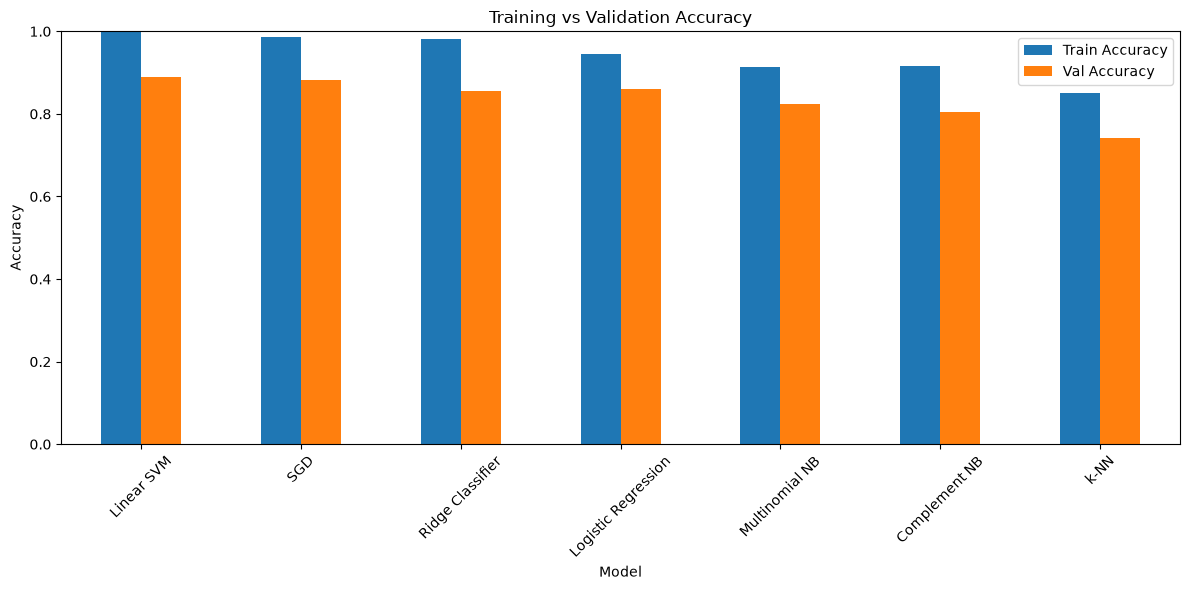

In [63]:
comparison = model_results.set_index("Model")

comparison[["Train Accuracy", "Val Accuracy"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Training vs Validation Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [64]:
C_values = [0.01, 0.1, 0.5, 1, 2, 5]

In [65]:
svm_tuning_results = []

for c in C_values:
    model = LinearSVC(C=c)
    
    model.fit(X_train_tfidf, y_train)
    
    train_pred = model.predict(X_train_tfidf)
    val_pred = model.predict(X_val_tfidf)
    
    train_acc = accuracy_score(y_train, train_pred)
    val_acc = accuracy_score(y_val, val_pred)
    
    train_f1 = f1_score(y_train, train_pred, average="macro")
    val_f1 = f1_score(y_val, val_pred, average="macro")
    
    svm_tuning_results.append({
        "C": c,
        "Train Accuracy": train_acc,
        "Val Accuracy": val_acc,
        "Train Macro F1": train_f1,
        "Val Macro F1": val_f1,
        "Accuracy Gap": train_acc - val_acc,
        "Macro F1 Gap": train_f1 - val_f1
    })

In [66]:
svm_tuning_df = pd.DataFrame(svm_tuning_results)

svm_tuning_df.sort_values(
    by="Val Macro F1",
    ascending=False
).round(4)

,C,Train Accuracy,Val Accuracy,Train Macro F1,Val Macro F1,Accuracy Gap,Macro F1 Gap
4,2.00,0.9986,0.8921,0.9986,0.8932,0.1064,0.1054
3,1.00,0.9973,0.8901,0.9974,0.8912,0.1072,0.1062
2,0.50,0.9940,0.8851,0.9940,0.8867,0.1089,0.1072
5,5.00,0.9993,0.8851,0.9994,0.8848,0.1142,0.1146
1,0.10,0.9597,0.8671,0.9558,0.8643,0.0925,0.0915
0,0.01,0.8725,0.8132,0.8603,0.7967,0.0593,0.0636


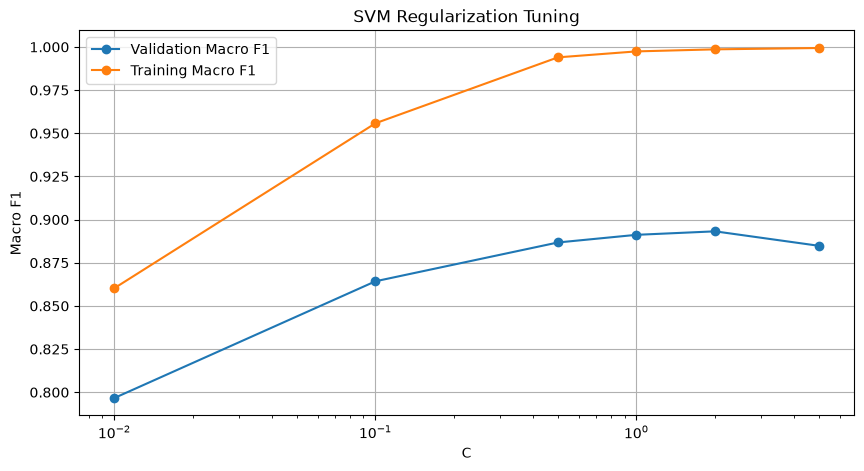

In [67]:
plt.figure(figsize=(10, 5))

plt.plot(
    svm_tuning_df["C"],
    svm_tuning_df["Val Macro F1"],
    marker="o",
    label="Validation Macro F1"
)

plt.plot(
    svm_tuning_df["C"],
    svm_tuning_df["Train Macro F1"],
    marker="o",
    label="Training Macro F1"
)

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Macro F1")
plt.title("SVM Regularization Tuning")
plt.legend()
plt.grid(True)
plt.show()

In [68]:
from sklearn.feature_extraction.text import TfidfVectorizer

char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    sublinear_tf=True
)

In [69]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [0.1, 0.5, 1, 2, 5],
    "class_weight": [None, "balanced"]
}

In [70]:
svm_search = GridSearchCV(
    estimator=LinearSVC(),
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

In [71]:
svm_search.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearSVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 0.5, ...], 'class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during 

In [72]:
svm_search.fit(X_train_tfidf, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearSVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 0.5, ...], 'class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during 

In [73]:
best_svm = svm_search.best_estimator_

y_val_pred_tuned = best_svm.predict(X_val_tfidf)

tuned_val_accuracy = accuracy_score(y_val, y_val_pred_tuned)
tuned_val_macro_f1 = f1_score(y_val, y_val_pred_tuned, average="macro")
tuned_val_weighted_f1 = f1_score(
    y_val,
    y_val_pred_tuned,
    average="weighted"
)

print("Validation Accuracy:", tuned_val_accuracy)
print("Validation Macro F1:", tuned_val_macro_f1)
print("Validation Weighted F1:", tuned_val_weighted_f1)

Validation Accuracy: 0.8921078921078921
Validation Macro F1: 0.8932006660235423
Validation Weighted F1: 0.8921358354713842


In [74]:
tuned_train_pred = best_svm.predict(X_train_tfidf)

tuned_train_accuracy = accuracy_score(y_train, tuned_train_pred)
tuned_train_macro_f1 = f1_score(y_train, tuned_train_pred, average="macro")

print("Train Accuracy:", tuned_train_accuracy)
print("Val Accuracy:", tuned_val_accuracy)
print("Accuracy Gap:", tuned_train_accuracy - tuned_val_accuracy)

print("Train Macro F1:", tuned_train_macro_f1)
print("Val Macro F1:", tuned_val_macro_f1)
print("Macro F1 Gap:", tuned_train_macro_f1 - tuned_val_macro_f1)

Train Accuracy: 0.9985558764718951
Val Accuracy: 0.8921078921078921
Accuracy Gap: 0.10644798436400305
Train Macro F1: 0.9986012902900357
Val Macro F1: 0.8932006660235423
Macro F1 Gap: 0.10540062426649344


In [75]:
print("Best parameters:", svm_search.best_params_)
print("Best CV Macro F1:", svm_search.best_score_)

Best parameters: {'C': 2, 'class_weight': None}
Best CV Macro F1: 0.867146475519402


In [76]:
from sklearn.pipeline import Pipeline

svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("svm", LinearSVC())
])

In [77]:
param_grid_pipeline = {
    "svm__C": [0.1, 0.5, 1, 2, 5],
    "svm__class_weight": [None, "balanced"]
}

In [78]:
svm_search_pipeline = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid_pipeline,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

In [79]:
svm_search_pipeline.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...LinearSVC())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svm__C': [0.1, 0.5, ...], 'svm__class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity o

In [80]:
best_svm_pipeline = svm_search_pipeline.best_estimator_

y_val_pred_tuned = best_svm_pipeline.predict(X_val)

tuned_val_accuracy = accuracy_score(y_val, y_val_pred_tuned)
tuned_val_macro_f1 = f1_score(y_val, y_val_pred_tuned, average="macro")
tuned_val_weighted_f1 = f1_score(
    y_val,
    y_val_pred_tuned,
    average="weighted"
)

print("Validation Accuracy:", tuned_val_accuracy)
print("Validation Macro F1:", tuned_val_macro_f1)
print("Validation Weighted F1:", tuned_val_weighted_f1)

Validation Accuracy: 0.8901098901098901
Validation Macro F1: 0.8911770406239142
Validation Weighted F1: 0.8896307549011453


In [81]:
print("Best parameters:", svm_search_pipeline.best_params_)
print("Best CV Macro F1:", svm_search_pipeline.best_score_)

Best parameters: {'svm__C': 1, 'svm__class_weight': None}
Best CV Macro F1: 0.862279418484745


In [82]:
char_tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    sublinear_tf=True
)

In [83]:
X_train_char = char_tfidf.fit_transform(X_train)
X_val_char = char_tfidf.transform(X_val)

In [84]:
print("Character TF-IDF training shape:", X_train_char.shape)
print("Character TF-IDF validation shape:", X_val_char.shape)

Character TF-IDF training shape: (9002, 31237)
Character TF-IDF validation shape: (1001, 31237)


In [85]:
char_svm = LinearSVC()

start = time.time()

char_svm.fit(X_train_char, y_train)

char_svm_training_time = time.time() - start

In [86]:
start = time.time()

y_val_pred_char = char_svm.predict(X_val_char)

char_svm_prediction_time = time.time() - start

In [87]:
char_svm_accuracy = accuracy_score(y_val, y_val_pred_char)
char_svm_macro_f1 = f1_score(y_val, y_val_pred_char, average="macro")
char_svm_weighted_f1 = f1_score(
    y_val,
    y_val_pred_char,
    average="weighted"
)

print("Validation Accuracy:", char_svm_accuracy)
print("Validation Macro F1:", char_svm_macro_f1)
print("Validation Weighted F1:", char_svm_weighted_f1)
print("Training Time:", char_svm_training_time)
print("Prediction Time:", char_svm_prediction_time)

Validation Accuracy: 0.913086913086913
Validation Macro F1: 0.9146623853164205
Validation Weighted F1: 0.9128201807192154
Training Time: 11.86089301109314
Prediction Time: 0.08204388618469238


In [88]:
y_train_pred_char = char_svm.predict(X_train_char)

char_train_accuracy = accuracy_score(y_train, y_train_pred_char)
char_train_macro_f1 = f1_score(y_train, y_train_pred_char, average="macro")

print("Train Accuracy:", char_train_accuracy)
print("Val Accuracy:", char_svm_accuracy)
print("Accuracy Gap:", char_train_accuracy - char_svm_accuracy)

print("Train Macro F1:", char_train_macro_f1)
print("Val Macro F1:", char_svm_macro_f1)
print("Macro F1 Gap:", char_train_macro_f1 - char_svm_macro_f1)

Train Accuracy: 0.9972228393690291
Val Accuracy: 0.913086913086913
Accuracy Gap: 0.08413592628211608
Train Macro F1: 0.997349106439701
Val Macro F1: 0.9146623853164205
Macro F1 Gap: 0.08268672112328046


In [89]:
char_svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char")),
    ("svm", LinearSVC())
])

In [90]:
char_param_grid = {
    "tfidf__ngram_range": [(3, 5), (3, 6)],
    "tfidf__min_df": [2],
    "svm__C": [0.5, 1, 2]
}


In [91]:
char_search = GridSearchCV(
    estimator=char_svm_pipeline,
    param_grid=char_param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

In [92]:
char_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...LinearSVC())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svm__C': [0.5, 1, ...], 'tfidf__min_df': [2], 'tfidf__ngram_range': [(3, ...), (3, ...)]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0C

In [93]:
print("Best parameters:", char_search.best_params_)
print("Best CV Macro F1:", char_search.best_score_)

Best parameters: {'svm__C': 2, 'tfidf__min_df': 2, 'tfidf__ngram_range': (3, 5)}
Best CV Macro F1: 0.8885441491198461


In [94]:
best_char_svm = char_search.best_estimator_

y_val_pred_char_tuned = best_char_svm.predict(X_val)

char_tuned_val_accuracy = accuracy_score(y_val, y_val_pred_char_tuned)
char_tuned_val_macro_f1 = f1_score(
    y_val,
    y_val_pred_char_tuned,
    average="macro"
)
char_tuned_val_weighted_f1 = f1_score(
    y_val,
    y_val_pred_char_tuned,
    average="weighted"
)

print("Validation Accuracy:", char_tuned_val_accuracy)
print("Validation Macro F1:", char_tuned_val_macro_f1)
print("Validation Weighted F1:", char_tuned_val_weighted_f1)

Validation Accuracy: 0.9150849150849151
Validation Macro F1: 0.9143027354725545
Validation Weighted F1: 0.9148868411441391


In [95]:
y_train_pred_char_tuned = best_char_svm.predict(X_train)

tuned_char_train_accuracy = accuracy_score(y_train, y_train_pred_char_tuned)
tuned_char_train_macro_f1 = f1_score(
    y_train,
    y_train_pred_char_tuned,
    average="macro"
)

print("Train Accuracy:", tuned_char_train_accuracy)
print("Val Accuracy:", char_tuned_val_accuracy)
print("Accuracy Gap:", tuned_char_train_accuracy - char_tuned_val_accuracy)

print("Train Macro F1:", tuned_char_train_macro_f1)
print("Val Macro F1:", char_tuned_val_macro_f1)
print("Macro F1 Gap:", tuned_char_train_macro_f1 - char_tuned_val_macro_f1)

Train Accuracy: 0.9991113085980893
Val Accuracy: 0.9150849150849151
Accuracy Gap: 0.0840263935131742
Train Macro F1: 0.9991767528585784
Val Macro F1: 0.9143027354725545
Macro F1 Gap: 0.08487401738602396


In [96]:
correct = (y_val == y_val_pred_char)

print("Correct predictions:", correct.sum())
print("Incorrect predictions:", (~correct).sum())
print("Total validation samples:", len(y_val))

Correct predictions: 914
Incorrect predictions: 87
Total validation samples: 1001


In [97]:
errors = train_df.loc[X_val.index].copy()

errors["predicted_category"] = y_val_pred_char

errors = errors[
    errors["category"] != errors["predicted_category"]
]

errors[["text", "category", "predicted_category"]].head(20)

,text,category,predicted_category
3851,Am I supposed to verify my identity?,why_verify_identity,verify_my_identity
8443,Tell me more about getting a virtual disposabl...,get_disposable_virtual_card,disposable_card_limits
9510,I used my card to get cash then I was charged ...,cash_withdrawal_charge,card_payment_fee_charged
2453,How can we correct a mistake on an ATM transac...,wrong_amount_of_cash_received,cancel_transfer
3800,Why should I have to prove my identity?,why_verify_identity,unable_to_verify_identity
2969,Can I use this app for any currency?,supported_cards_and_currencies,exchange_via_app
1411,Is there a way to make my money usable in anot...,exchange_via_app,country_support
7141,My account transfer was blocked.,beneficiary_not_allowed,pin_blocked
8763,What happened to the transfer I did?,balance_not_updated_after_bank_transfer,pending_transfer
9881,Can I use my card in Austria?,country_support,card_acceptance


In [98]:
from sklearn.metrics import confusion_matrix

In [99]:
labels = sorted(train_df["category"].unique())

cm = confusion_matrix(
    y_val,
    y_val_pred_char,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

In [100]:
cm_without_diagonal = cm.copy()

np.fill_diagonal(cm_without_diagonal, 0)

cm_df = pd.DataFrame(
    cm_without_diagonal,
    index=labels,
    columns=labels
)

In [101]:
top_confusions = (
    cm_df
    .stack()
    .sort_values(ascending=False)
)

top_confusions.head(15)

balance_not_updated_after_bank_transfer  pending_transfer                           3
get_disposable_virtual_card              disposable_card_limits                     2
country_support                          card_acceptance                            2
why_verify_identity                      verify_my_identity                         2
                                         unable_to_verify_identity                  2
direct_debit_payment_not_recognised      card_payment_not_recognised                2
top_up_failed                            pending_top_up                             2
pending_card_payment                     reverted_card_payment?                     1
failed_transfer                          reverted_card_payment?                     1
transfer_timing                          balance_not_updated_after_bank_transfer    1
declined_cash_withdrawal                 declined_transfer                          1
pending_card_payment                     pending_top_u

In [102]:
errors[
    (errors["category"] == "balance_not_updated_after_bank_transfer") &
    (errors["predicted_category"] == "pending_transfer")
][["text", "category", "predicted_category"]]

,text,category,predicted_category
8763,What happened to the transfer I did?,balance_not_updated_after_bank_transfer,pending_transfer
8666,How long does it take for a transfer to post,balance_not_updated_after_bank_transfer,pending_transfer
8715,MY transfer has still not appeared.,balance_not_updated_after_bank_transfer,pending_transfer


In [103]:
errors_correct = pd.concat([
    train_df.loc[X_val.index],
], axis=1)

errors_correct["predicted_category"] = y_val_pred_char

correct_examples = errors_correct[
    errors_correct["category"].isin([
        "balance_not_updated_after_bank_transfer",
        "pending_transfer"
    ]) &
    (errors_correct["category"] == errors_correct["predicted_category"])
]

correct_examples[
    ["text", "category"]
].sample(10, random_state=42)

,text,category
6076,Why is there a pending time on my transfer?,pending_transfer
8662,I transferred some funds but I don't see it,balance_not_updated_after_bank_transfer
8615,Hello. Can you help figure out why the recent ...,balance_not_updated_after_bank_transfer
6113,Why is my transfer stuck on pending?,pending_transfer
8724,I made a transfer from France a couple days ag...,balance_not_updated_after_bank_transfer
8669,Tell me why my balance did not change when I t...,balance_not_updated_after_bank_transfer
6061,My transfer hasn't appeared yet,pending_transfer
6013,How long is a transfer in the pending status?,pending_transfer
8754,Help me find the transfer that I did.,balance_not_updated_after_bank_transfer
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer


In [104]:
from sklearn.pipeline import Pipeline, FeatureUnion

In [105]:
combined_features = FeatureUnion([
    (
        "word_tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "char_tfidf",
        TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True
        )
    )
])

In [106]:
combined_svm = Pipeline([
    ("features", combined_features),
    ("svm", LinearSVC(C=1))
])

In [107]:
combined_svm.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('svm', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](77,)","['Refund_not_showing_up','activate_my_card','age_limit',..., 'why_verify_identity','wrong_amount_of_cash_received', 'wrong_exchange_rate_for_cash_withdrawal']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word_tfidf', ...), ('char_tfidf', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [108]:
y_val_pred_combined = combined_svm.predict(X_val)

combined_accuracy = accuracy_score(y_val, y_val_pred_combined)
combined_macro_f1 = f1_score(y_val, y_val_pred_combined, average="macro")
combined_weighted_f1 = f1_score(
    y_val,
    y_val_pred_combined,
    average="weighted"
)

print("Validation Accuracy:", combined_accuracy)
print("Validation Macro F1:", combined_macro_f1)
print("Validation Weighted F1:", combined_weighted_f1)

Validation Accuracy: 0.9170829170829171
Validation Macro F1: 0.9181135220698573
Validation Weighted F1: 0.9171092163461669


In [109]:
combined_train_pred = combined_svm.predict(X_train)

combined_train_accuracy = accuracy_score(y_train, combined_train_pred)
combined_train_macro_f1 = f1_score(
    y_train,
    combined_train_pred,
    average="macro"
)

print("Train Accuracy:", combined_train_accuracy)
print("Val Accuracy:", combined_accuracy)
print("Accuracy Gap:", combined_train_accuracy - combined_accuracy)

print("Train Macro F1:", combined_train_macro_f1)
print("Val Macro F1:", combined_macro_f1)
print("Macro F1 Gap:", combined_train_macro_f1 - combined_macro_f1)

Train Accuracy: 0.9990002221728504
Val Accuracy: 0.9170829170829171
Accuracy Gap: 0.08191730508993333
Train Macro F1: 0.9990481905180344
Val Macro F1: 0.9181135220698573
Macro F1 Gap: 0.0809346684481771


In [110]:
combined_param_grid = {
    "features__word_tfidf__ngram_range": [(1, 2), (1, 3)],
    "features__char_tfidf__ngram_range": [(3, 5), (3, 6)],
    "svm__C": [0.5, 1, 2]
}

In [111]:
combined_search = GridSearchCV(
    estimator=combined_svm,
    param_grid=combined_param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1
)

In [112]:
combined_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...earSVC(C=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'features__char_tfidf__ngram_range': [(3, ...), (3, ...)], 'features__word_tfidf__ngram_range': [(1, ...), (1, ...)], 'svm__C': [0.5, 1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [113]:
print("Best parameters:", combined_search.best_params_)
print("Best CV Macro F1:", combined_search.best_score_)

Best parameters: {'features__char_tfidf__ngram_range': (3, 5), 'features__word_tfidf__ngram_range': (1, 2), 'svm__C': 1}
Best CV Macro F1: 0.8839508073926162


In [114]:
best_combined_svm = combined_search.best_estimator_

y_val_pred_combined_tuned = best_combined_svm.predict(X_val)

combined_tuned_accuracy = accuracy_score(
    y_val,
    y_val_pred_combined_tuned
)

combined_tuned_macro_f1 = f1_score(
    y_val,
    y_val_pred_combined_tuned,
    average="macro"
)

combined_tuned_weighted_f1 = f1_score(
    y_val,
    y_val_pred_combined_tuned,
    average="weighted"
)

print("Validation Accuracy:", combined_tuned_accuracy)
print("Validation Macro F1:", combined_tuned_macro_f1)
print("Validation Weighted F1:", combined_tuned_weighted_f1)

Validation Accuracy: 0.9170829170829171
Validation Macro F1: 0.9181135220698573
Validation Weighted F1: 0.9171092163461669


In [117]:
from sklearn.metrics import classification_report

report = classification_report(
    y_val,
    y_val_pred_combined,
    output_dict=True,
    zero_division=0
)

class_performance = pd.DataFrame(report).T

class_performance = class_performance.loc[
    sorted(train_df["category"].unique())
]

class_performance = class_performance.sort_values(
    by="f1-score",
    ascending=True
)

class_performance.head(10)

,precision,recall,f1-score,support
topping_up_by_card,0.777778,0.700000,0.736842,10.0
card_acceptance,0.714286,0.833333,0.769231,6.0
top_up_reverted,0.750000,0.800000,0.774194,15.0
top_up_failed,0.846154,0.733333,0.785714,15.0
compromised_card,0.692308,1.000000,0.818182,9.0
receiving_money,0.875000,0.777778,0.823529,9.0
balance_not_updated_after_bank_transfer,0.823529,0.823529,0.823529,17.0
supported_cards_and_currencies,0.750000,0.923077,0.827586,13.0
pending_card_payment,0.923077,0.750000,0.827586,16.0
transfer_into_account,0.769231,0.909091,0.833333,11.0


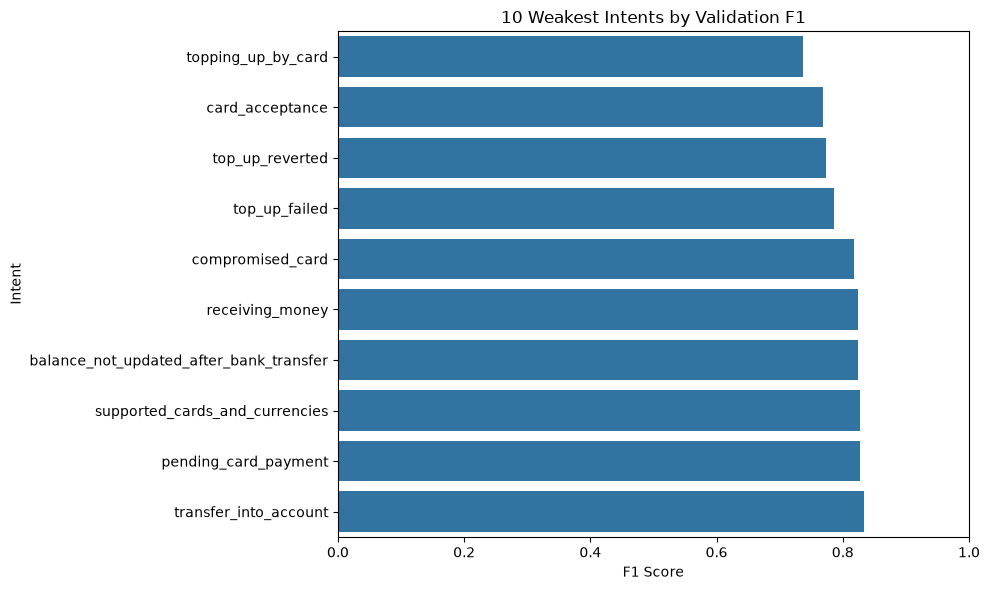

In [118]:
top10_weakest = class_performance.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top10_weakest["f1-score"],
    y=top10_weakest.index
)

plt.xlim(0, 1)
plt.xlabel("F1 Score")
plt.ylabel("Intent")
plt.title("10 Weakest Intents by Validation F1")
plt.tight_layout()
plt.show()

In [119]:
combined_errors = train_df.loc[X_val.index].copy()

combined_errors["predicted_category"] = y_val_pred_combined

combined_errors = combined_errors[
    combined_errors["category"] != combined_errors["predicted_category"]
]

combined_errors[
    ["text", "category", "predicted_category"]
].head(20)

,text,category,predicted_category
9510,I used my card to get cash then I was charged ...,cash_withdrawal_charge,card_payment_fee_charged
2453,How can we correct a mistake on an ATM transac...,wrong_amount_of_cash_received,cancel_transfer
6686,"Its been 3 days, How long will my transfer tak...",transfer_timing,transfer_not_received_by_recipient
3800,Why should I have to prove my identity?,why_verify_identity,unable_to_verify_identity
2969,Can I use this app for any currency?,supported_cards_and_currencies,exchange_via_app
1411,Is there a way to make my money usable in anot...,exchange_via_app,verify_source_of_funds
7141,My account transfer was blocked.,beneficiary_not_allowed,pin_blocked
8763,What happened to the transfer I did?,balance_not_updated_after_bank_transfer,top_up_reverted
9881,Can I use my card in Austria?,country_support,card_acceptance
4755,Purchases I did not make are appearing in my b...,direct_debit_payment_not_recognised,card_payment_not_recognised


In [120]:
combined_cm = confusion_matrix(
    y_val,
    y_val_pred_combined,
    labels=labels
)

combined_cm_no_diag = combined_cm.copy()

np.fill_diagonal(combined_cm_no_diag, 0)

combined_cm_df = pd.DataFrame(
    combined_cm_no_diag,
    index=labels,
    columns=labels
)

top_combined_confusions = (
    combined_cm_df
    .stack()
    .sort_values(ascending=False)
)

top_combined_confusions.head(15)

balance_not_updated_after_bank_transfer  pending_transfer                  2
direct_debit_payment_not_recognised      card_payment_not_recognised       2
topping_up_by_card                       top_up_reverted                   2
why_verify_identity                      unable_to_verify_identity         2
top_up_failed                            pending_top_up                    2
country_support                          card_acceptance                   2
beneficiary_not_allowed                  pending_card_payment              1
                                         pin_blocked                       1
receiving_money                          topping_up_by_card                1
card_not_working                         order_physical_card               1
card_acceptance                          card_not_working                  1
pending_cash_withdrawal                  cash_withdrawal_charge            1
                                         cash_withdrawal_not_recognised    1

In [121]:
X_full_train = pd.concat([X_train, X_val])
y_full_train = pd.concat([y_train, y_val])

print("Final training samples:", len(X_full_train))

Final training samples: 10003


In [122]:
final_model = Pipeline([
    ("features", FeatureUnion([
        (
            "word_tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                sublinear_tf=True
            )
        ),
        (
            "char_tfidf",
            TfidfVectorizer(
                analyzer="char",
                ngram_range=(3, 5),
                min_df=2,
                sublinear_tf=True
            )
        )
    ])),
    ("svm", LinearSVC(C=1))
])

In [123]:
start = time.time()

final_model.fit(X_full_train, y_full_train)

final_training_time = time.time() - start

print("Final training time:", final_training_time)

Final training time: 16.2101731300354


In [124]:
X_test = test_df["text"]
y_test = test_df["category"]

y_test_pred = final_model.predict(X_test)

In [125]:
test_accuracy = accuracy_score(y_test, y_test_pred)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

test_weighted_f1 = f1_score(
    y_test,
    y_test_pred,
    average="weighted"
)

print("TEST RESULTS")
print("----------------------------")
print("Accuracy:", test_accuracy)
print("Macro F1:", test_macro_f1)
print("Weighted F1:", test_weighted_f1)

TEST RESULTS
----------------------------
Accuracy: 0.9081168831168831
Macro F1: 0.9082719339011498
Weighted F1: 0.9082719339011495


In [126]:
print(
    classification_report(
        y_test,
        y_test_pred,
        zero_division=0
    )
)

                                                  precision    recall  f1-score   support

                           Refund_not_showing_up       0.97      0.95      0.96        40
                                activate_my_card       0.97      0.95      0.96        40
                                       age_limit       0.95      1.00      0.98        40
                         apple_pay_or_google_pay       1.00      1.00      1.00        40
                                     atm_support       0.95      0.95      0.95        40
                                automatic_top_up       0.97      0.97      0.97        40
         balance_not_updated_after_bank_transfer       0.75      0.75      0.75        40
balance_not_updated_after_cheque_or_cash_deposit       0.95      0.95      0.95        40
                         beneficiary_not_allowed       1.00      0.95      0.97        40
                                 cancel_transfer       1.00      0.95      0.97        40
         

In [127]:
import joblib

model_path = "../model/banking_intent_classifier.joblib"

joblib.dump(final_model, model_path)

print("Model saved to:", model_path)

Model saved to: ../model/banking_intent_classifier.joblib


In [128]:
loaded_model = joblib.load("../model/banking_intent_classifier.joblib")

print("Model loaded successfully.")

Model loaded successfully.


In [129]:
sample_text = "My card has not arrived yet"

prediction = loaded_model.predict([sample_text])

print("Text:", sample_text)
print("Predicted intent:", prediction[0])

Text: My card has not arrived yet
Predicted intent: card_arrival
